# Leave-One-Out Analysis

This notebook demonstrates how to use the leave-one-out cross validation analysis of [Wellbanks et al. 2023](https://ui.adsabs.harvard.edu/abs/2023AJ....165..112W/abstract).

We compare two transmission retrievals of the same HST spectrum:a baseline free-chemistry model with CH4, CO2, and CO, and the same model with H2O added back in. 
Both retrievals use the Dynesty backend and the same forward model. The custom `retrieval_model_spec_iso` function now accepts a `ModelContext` and `PhysicalParams`, and it is explicitly marked as a differentiable retrieval model so Dynesty can use the JAX-aware runtime path.

### In this tutorial:
- Running a transmission retrieval using Dynesty
- Defining a custom model generating function
- Performing leave-one-out cross validation analysis

In [1]:
import os
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_probability.substrates.jax as tfp

import petitRADTRANS as prt
from petitRADTRANS import physical_constants as cst
from petitRADTRANS.chemistry import clouds
from petitRADTRANS.chemistry.core import get_abundances
from petitRADTRANS.retrieval import Retrieval, RetrievalConfig
from petitRADTRANS.retrieval.models import (
    MODEL_CONTRACT_DIFFERENTIABLE,
    _compute_gravity,
    calculate_transmission_spectrum_runtime,
    initialize_pressure,
 )
from petitRADTRANS.retrieval.runtime import (
    ModelContext,
    ModelInputs,
    ModelResult,
    PhysicalParams,
    _radtrans_wavelength_grid,
 )
from petitRADTRANS.temperature_profiles import isothermal_temperature_profile

tfpd = tfp.distributions

In [ ]:
package_root = Path(prt.__file__).resolve().parent
repo_root = package_root.parent
example_data_file = Path("retrievals/transmission/observations/HST/hst_example_clear_spec.txt")

output_root = repo_root / "retrieval_outputs" / "leave_one_out_dynesty"
output_root.mkdir(parents=True, exist_ok=True)

observations = np.loadtxt(example_data_file.resolve())
wavelengths = observations[:, 0]
spectrum = observations[:, 1]
uncertainties = observations[:, 2]
wavelength_boundaries = (
    0.95 * float(wavelengths.min()),
    1.05 * float(wavelengths.max()),
)

print(f"Example data: {example_data_file}")
print(f"Output directory: {output_root}")
print(
    f"Wavelength coverage: {wavelengths.min():.3f} to {wavelengths.max():.3f} micron"
)
print(f"Number of data points: {wavelengths.size}")

Example data: /Users/nasedkin/python-packages/petitRADTRANS/docs/content/notebooks/retrievals/transmission/observations/HST/hst_example_clear_spec.txt
Output directory: /Users/nasedkin/python-packages/petitRADTRANS/retrieval_outputs/leave_one_out_dynesty
Wavelength coverage: 1.138 to 1.637 micron
Number of data points: 20


## Differentiable model functions

In pRT4, custom retrieval models should follow the differentiable signature:

```python
def retrieval_model_spec_iso(
    model_context: ModelContext,
    physical_params: PhysicalParams,
    pt_plot_mode: bool = False,
 ) -> ModelResult:
    ...
```

The example below expands the same steps used inside the built-in `isothermal_transmission` model:

1. initialize the pressure grid,
2. build the isothermal temperature profile,
3. compute abundances and mean molecular weights with `get_abundances`,
4. set up simple cloud and haze controls,
5. assemble `ModelInputs`,
6. call the transmission-spectrum calculator.


In [3]:
def retrieval_model_spec_iso(
    model_context: ModelContext,
    physical_params: PhysicalParams,
    pt_plot_mode: bool = False,
 ) -> ModelResult:
    """Isothermal transmission model.

    This mirrors the main stages inside the built-in
    ``isothermal_transmission`` implementation so that users can adapt the
    pattern for their own transmission forward models.
    """
    p_use, p_global = initialize_pressure(
        model_context.radtrans.pressures / 1e6,
        physical_params,
        model_context.adaptive_mesh_refinement,
    )

    reference_pressure = 100.0
    if "reference_pressure" in physical_params.keys():
        reference_pressure = physical_params["reference_pressure"]

    temperatures = isothermal_temperature_profile(
        p_use,
        physical_params["temperature"],
    )
    gravity, planet_radius = _compute_gravity(physical_params)

    abundances, mean_molar_masses, small_index, _p_bases = get_abundances(
        pressures=p_use,
        temperatures=temperatures,
        parameters=physical_params,
        line_species=model_context.radtrans.line_species,
        cloud_species=model_context.radtrans.cloud_species,
        adaptive_mesh_refinement=model_context.adaptive_mesh_refinement,
    )

    if abundances is None:
        wavelengths = _radtrans_wavelength_grid(model_context.radtrans)
        return ModelResult.make_nan_result(wavelengths)

    if pt_plot_mode:
        return ModelResult(
            kind="pt_profile",
            pressures=p_use[small_index],
            temperatures=temperatures[small_index],
        )

    if model_context.adaptive_mesh_refinement:
        temperatures = temperatures[small_index]
        pressures = p_global[small_index]
        mean_molar_masses = mean_molar_masses[small_index]
        model_context.radtrans.pressures = pressures * 1e6
    else:
        pressures = p_use

    if pressures.shape[0] != model_context.radtrans.pressures.shape[0]:
        wavelengths = _radtrans_wavelength_grid(model_context.radtrans)
        return ModelResult.make_nan_result(wavelengths)

    pcloud, power_law_opacity_coefficient, haze_factor, power_law_opacity_350nm = (
        clouds.setup_simple_clouds_hazes(physical_params)
    )
    cloud_properties = clouds.setup_clouds(
        pressures,
        physical_params,
        model_context.radtrans.cloud_species,
    )
    (
        sigma_lnorm,
        cloud_f_sed,
        eddy_diffusion_coefficients,
        cloud_hansen_b,
        cloud_particle_mean_radii,
        cloud_fraction,
        patchy_clouds,
        distribution,
    ) = cloud_properties

    model_inputs = ModelInputs(
        pressures=pressures,
        temperatures=temperatures,
        abundances=abundances,
        mean_molar_masses=mean_molar_masses,
        gravity=gravity,
        planet_radius=planet_radius,
        reference_pressure=reference_pressure,
        opaque_cloud_top_pressure=pcloud,
        sigma_lnorm=sigma_lnorm,
        cloud_particle_mean_radii=cloud_particle_mean_radii,
        cloud_f_sed=cloud_f_sed,
        eddy_diffusion_coefficients=eddy_diffusion_coefficients,
        haze_factor=haze_factor,
        power_law_opacity_coefficient=power_law_opacity_coefficient,
        power_law_opacity_350nm=power_law_opacity_350nm,
        cloud_hansen_b=cloud_hansen_b,
        cloud_fraction=cloud_fraction,
        patchy_clouds=patchy_clouds,
        cloud_particle_radius_distribution=distribution,
        stellar_radius=physical_params["stellar_radius"],
    )

    return calculate_transmission_spectrum_runtime(
        model_context,
        model_inputs,
    )

setattr(
    retrieval_model_spec_iso,
    "_prt_model_contract",
    MODEL_CONTRACT_DIFFERENTIABLE,
 )

## Retrieval configuration helper

Both retrievals share the same physical parameters, data file, and Dynesty configuration. The only difference is the set of retrieved line species. We build both `RetrievalConfig` objects from one helper so the comparison stays controlled.

In [12]:
pressures = jnp.logspace(-6.0, 2.0, 100)

corner_labels = {
    "1H2-16O__POKAZATEL": r"$\log X_{\rm H_2O}$",
    "12C-1H4__HITEMP": r"$\log X_{\rm CH_4}$",
    "12C-16O2__UCL-4000": r"$\log X_{\rm CO_2}$",
    "C-O-NatAbund__HITEMP": r"$\log X_{\rm CO}$",
}

def build_leave_one_out_config(retrieval_name, line_species):
    retrieval_config = RetrievalConfig(
        retrieval_name=retrieval_name,
        run_mode="evaluate",
        sampler_type="dynesty",
        pressures=pressures,
        adaptive_mesh_refinement=False,
        scattering_in_emission=False,
    )

    retrieval_config.add_parameter(
        name="stellar_radius",
        is_free_parameter=False,
        value=0.651 * cst.r_sun,
        plot_in_corner=False,
    )
    retrieval_config.add_parameter(
        name="reference_pressure",
        is_free_parameter=False,
        value=0.01,
        plot_in_corner=False,
    )
    retrieval_config.add_parameter(
        name="log_g",
        is_free_parameter=True,
        distribution=tfpd.Uniform(low=2.0, high=5.5),
        plot_in_corner=True,
        corner_ranges=(2.0, 5.5),
        corner_label=r"$\log(g)$",
    )
    retrieval_config.add_parameter(
        name="planet_radius",
        is_free_parameter=True,
        distribution=tfpd.Uniform(
            low=0.1 * cst.r_jup_mean,
            high=0.4 * cst.r_jup_mean,
        ),
        plot_in_corner=True,
        corner_ranges=(0.1, 0.4),
        corner_label=r"$R_{\rm P}$ ($R_{\rm Jup}$)",
        corner_transform=lambda radius: radius / cst.r_jup_mean,
    )
    retrieval_config.add_parameter(
        name="temperature",
        is_free_parameter=True,
        distribution=tfpd.Uniform(low=300.0, high=2000.0),
        plot_in_corner=True,
        corner_ranges=(300.0, 2000.0),
        corner_label="Temperature [K]",
    )
    retrieval_config.add_parameter(
        name="log_Pcloud",
        is_free_parameter=True,
        distribution=tfpd.Uniform(low=-6.0, high=2.0),
        plot_in_corner=True,
        corner_ranges=(-6.0, 2.0),
        corner_label=r"$\log P_{\rm cloud}$",
    )

    retrieval_config.set_rayleigh_species(["H2", "He"])
    retrieval_config.set_continuum_opacities(["H2--H2", "H2--He"])
    retrieval_config.set_line_species(
        list(line_species),
        use_equilibrium_chemistry=False,
        free_mass_fraction_limits=(-6.0, 0.0),
        plot_in_corner=True,
    )

    for species in retrieval_config.line_species:
        retrieval_config.parameters[species].corner_label = corner_labels.get(
            species, species
        )
        retrieval_config.parameters[species].corner_ranges = (-6.2, 0.2)

    retrieval_config.add_data(
        name="HST",
        path_to_observations=str(example_data_file),
        model_generating_function=retrieval_model_spec_iso,
        data_resolution=60,
        model_resolution=120,
        wavelength_boundaries=wavelength_boundaries,
        line_opacity_mode="c-k",
    )

    return retrieval_config

In [13]:
line_species_no_h2o = (
    "12C-1H4__HITEMP",
    "12C-16O2__UCL-4000",
    "C-O-NatAbund__HITEMP",
)
line_species_with_h2o = (
    "1H2-16O__POKAZATEL",
    *line_species_no_h2o,
 )

retrieval_config_no_h2o = build_leave_one_out_config(
    "hst_example_clear_spec_no_h2o_v4",
    line_species_no_h2o,
 )
retrieval_config_h2o = build_leave_one_out_config(
    "hst_example_clear_spec_with_h2o_v4",
    line_species_with_h2o,
 )

print("No-H2O retrieval line species:", retrieval_config_no_h2o.line_species)
print("H2O retrieval line species:", retrieval_config_h2o.line_species)

No-H2O retrieval line species: ('12C-1H4__HITEMP', '12C-16O2__UCL-4000', 'C-O-NatAbund__HITEMP')
H2O retrieval line species: ('1H2-16O__POKAZATEL', '12C-1H4__HITEMP', '12C-16O2__UCL-4000', 'C-O-NatAbund__HITEMP')


In [14]:
retrieval_no_h2o = Retrieval(
    configuration=retrieval_config_no_h2o,
    output_directory=str(output_root),
    evaluate_sample_spectra=False,
    reference_data_name="HST",
    use_prt_plot_style=True,
 )

retrieval_h2o = Retrieval(
    configuration=retrieval_config_h2o,
    output_directory=str(output_root),
    evaluate_sample_spectra=False,
    reference_data_name="HST",
    use_prt_plot_style=True,
 )

for retrieval in (retrieval_no_h2o, retrieval_h2o):
    retrieval.plotter.spec_xlabel = "Wavelength [micron]"
    retrieval.plotter.spec_ylabel = r"$(R_{\rm P}/R_*)^2$ [ppm]"
    retrieval.plotter.y_axis_scaling = 1e6
    retrieval.plotter.xscale = "linear"
    retrieval.plotter.yscale = "linear"
    retrieval.plotter.reference_data_name = "HST"
    retrieval.plotter.temp_limits = [150, 3000]
    retrieval.plotter.press_limits = [1e1, 1e-6]

runtime = retrieval_h2o._get_runtime()
for group in runtime.model_groups:
    print(
        {
            "source_name": group.source_name,
            "model_contract": group.model_contract,
            "observation_names": group.observation_names,
        }
    )

Setting up Radtrans object for data 'HST'...
Loading Radtrans opacities...
 Loading line opacities of species '12C-1H4__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__HITEMP.R120_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species '12C-16O2__UCL-4000.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R120_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'C-O-NatAbund__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R120_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Successfully loaded all line opacities
 Loading CIA opacities for H2--H2 from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/continuum/collision_induced_absorptions/H2--H2/H2--H2-Nat

## Running the Dynesty retrievals

The cells below keep both retrievals disabled by default so that opening the notebook does not start nested sampling automatically. Set the flags to `True` when you want to run or resume the two fits.

In [15]:
run_no_h2o_retrieval = True
run_h2o_retrieval = True

def run_dynesty_retrieval(retrieval):
    return retrieval.run(
        nlive=40,
        dlogz_init=0.5,
        bound="multi",
        sample="rwalk",
        use_jit=True,
        resume=True,
    )

if run_no_h2o_retrieval:
    run_dynesty_retrieval(retrieval_no_h2o)

if run_h2o_retrieval:
    run_dynesty_retrieval(retrieval_h2o)

Loading saved retrieval results for hst_example_clear_spec_no_h2o_v4 with dynesty
Loading saved retrieval results for hst_example_clear_spec_with_h2o_v4 with dynesty


## Loading posterior samples

Once the Dynesty runs finish, the helper below reloads the equal-weight posterior samples from `out_Dynesty`. If the files do not exist yet, the notebook prints a message and the later diagnostics cells remain guarded.

In [16]:
def load_results_if_available(retrieval):
    ret_name = retrieval.configuration.retrieval_name
    dynesty_dir = Path(retrieval.output_directory) / "out_Dynesty"
    samples_path = dynesty_dir / f"{ret_name}_samples.npz"
    params_path = dynesty_dir / f"{ret_name}_params.json"

    if not samples_path.exists() or not params_path.exists():
        print(f"Missing Dynesty outputs for {ret_name}.")
        return None, None, None, None

    sample_dict, parameter_dict = retrieval.get_samples(
        output_directory=retrieval.output_directory
    )
    return (
        sample_dict,
        parameter_dict,
        sample_dict[ret_name],
        parameter_dict[ret_name],
    )

(
    sample_dict_no_h2o,
    parameter_dict_no_h2o,
    samples_no_h2o,
    parameters_no_h2o,
 ) = load_results_if_available(retrieval_no_h2o)

(
    sample_dict_h2o,
    parameter_dict_h2o,
    samples_h2o,
    parameters_h2o,
 ) = load_results_if_available(retrieval_h2o)

## Computing leave-one-out diagnostics

`get_elpd_per_datapoint()` reads per-datapoint log-likelihood arrays from the evaluation folders. We therefore regenerate those arrays first for each retrieval, and then compare the H2O and no-H2O runs on the same data set.

In [ ]:
elpd_tot, elpd, pareto_k, delta_elpd = None, None, None, None

if samples_no_h2o is not None and samples_h2o is not None:
    samples_no_h2o = samples_no_h2o.T # Transpose to shape (num_samples, num_parameters + 1)
    samples_h2o = samples_h2o.T
    retrieval_no_h2o.get_log_likelihood_per_datapoint(
        samples_no_h2o[:,:-1],
        ret_name=retrieval_no_h2o.configuration.retrieval_name,
    )
    retrieval_h2o.get_log_likelihood_per_datapoint(
        samples_h2o[:,:-1],
        ret_name=retrieval_h2o.configuration.retrieval_name,
    )

    comparison_names = [
        retrieval_h2o.configuration.retrieval_name,
        retrieval_no_h2o.configuration.retrieval_name,
    ]
    elpd_tot, elpd, pareto_k, delta_elpd = retrieval_h2o.get_elpd_per_datapoint(
        ret_name=comparison_names,  # pyright: ignore[reportArgumentType]
    )

    for data_name, totals in elpd_tot.items():
        print(f"{data_name}:")
        print("  total ELPD:", totals)
else:
    print(
        "Run both retrievals, or place existing Dynesty outputs in the configured output directory, "
        "before computing leave-one-out diagnostics."
    )

HST:
  total ELPD: {'hst_example_clear_spec_with_h2o_v4': np.float64(169.749688749485), 'hst_example_clear_spec_no_h2o_v4': np.float64(163.29783412163334)}


## Plotting the best-fit spectrum

The two plots below color the data points by the Pareto-`k` diagnostic and by the per-point ELPD difference between the H2O and no-H2O retrievals.


Plotting Best-fit spectrum
Best fit likelihood = 172.32
Loading Radtrans opacities...
 Loading line opacities of species '1H2-16O__POKAZATEL.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R120_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species '12C-1H4__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__HITEMP.R120_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species '12C-16O2__UCL-4000.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R120_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'C-O-NatAbund__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R120_0.1-

/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/retrieval/plotting.py:1780: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


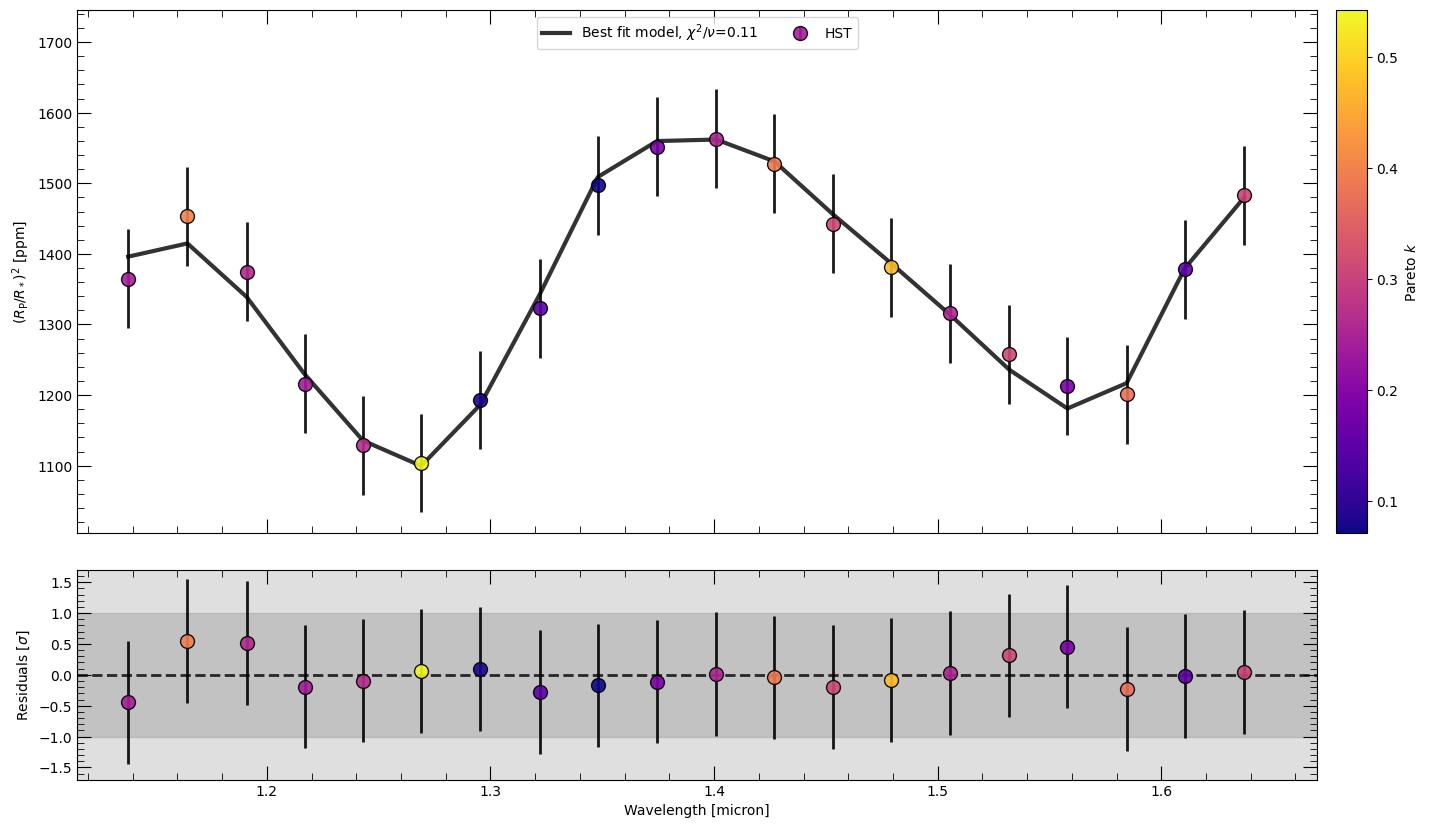

In [ ]:
if samples_h2o is not None and parameters_h2o is not None and pareto_k is not None:
    fig, ax, ax_r = retrieval_h2o.plot_spectra(
        samples_h2o.T, # Transpose back to shape (num_parameters + 1, num_samples) for plotting
        parameters_h2o,
        refresh=True,
        mode="bestfit",
        marker_color_type="pareto_k",
        marker_cmap=mpl.colormaps["plasma"],
        marker_label=r"Pareto $k$",
    )
    plt.show()
else:
    print(
        "Pareto-k plotting is available after the H2O retrieval results have been loaded."
    )


Plotting Best-fit spectrum
Best fit likelihood = 172.32
Loading Radtrans opacities...
 Loading line opacities of species '1H2-16O__POKAZATEL.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/H2O/1H2-16O/1H2-16O__POKAZATEL.R120_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species '12C-1H4__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CH4/12C-1H4/12C-1H4__HITEMP.R120_0.1-250mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species '12C-16O2__UCL-4000.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO2/12C-16O2/12C-16O2__UCL-4000.R120_0.3-50mu.ktable.petitRADTRANS.h5'... Done.
 Loading line opacities of species 'C-O-NatAbund__HITEMP.R120' from file '/Users/nasedkin/python-packages/petitRADTRANS/input_data/opacities/lines/correlated_k/CO/C-O-NatAbund/C-O-NatAbund__HITEMP.R120_0.1-

/Users/nasedkin/python-packages/petitRADTRANS/petitRADTRANS/retrieval/plotting.py:1780: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


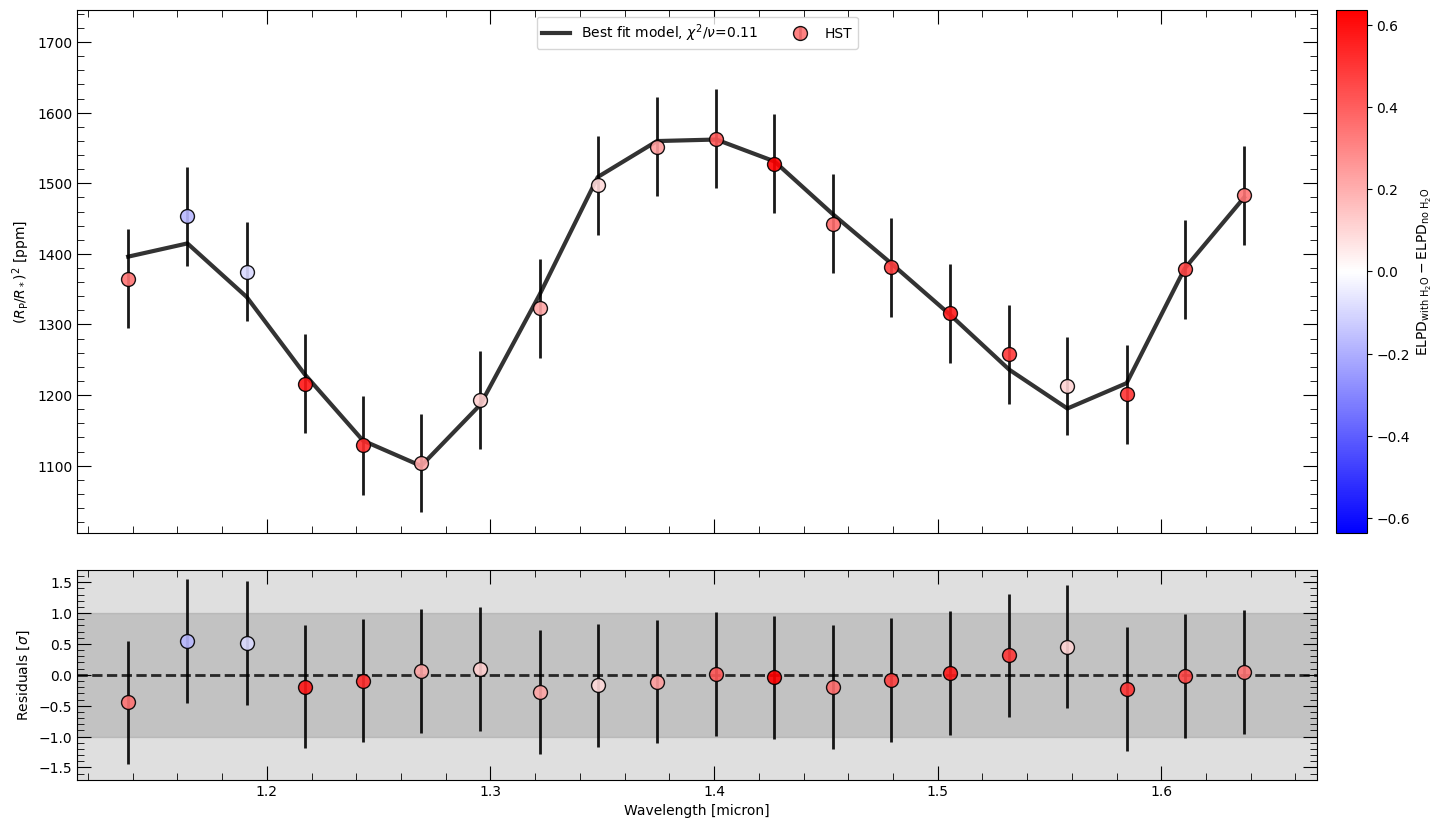

In [23]:
if samples_h2o is not None and parameters_h2o is not None and delta_elpd is not None:
    fig, ax, ax_r = retrieval_h2o.plot_spectra(
        samples_h2o.T,
        parameters_h2o,
        refresh=True,
        mode="bestfit",
        marker_color_type="delta_elpd",
        marker_cmap=mpl.colormaps["bwr"],
        marker_label=(
            r"$\mathrm{ELPD}_{\mathrm{with\ H_2O}} - "
            r"\mathrm{ELPD}_{\mathrm{no\ H_2O}}$"
        ),
    )
    plt.show()
else:
    print(
        "Delta-ELPD plotting is available after leave-one-out diagnostics have been computed."
    )